# Ensemble Learning บน Iris: Bagging (Parallel) และ Boosting (Sequential)
**Classwork สุดท้าย · วิชา Machine Learning (รศ.ดร.ปริญญา สงวนสัตย์)**

ผู้ทำ: ปฏิมา ถิ่นสำราญ (6752300461) · รุจิรัตน์ แสงชัย (6752300739)

**โจทย์**: เขียน Bagging และ Boosting เองบนชุดข้อมูล Iris
- ข้อมูล: Iris จาก Hugging Face `scikit-learn/iris` แบ่ง train/test **80/20** แบบ stratified เทรนด้วย 80% เท่านั้น
- base classifier ใช้ `DecisionTreeClassifier` จาก sklearn (โจทย์อนุญาต)
- ตัวอัลกอริทึม ensemble เขียนเองทั้งหมดใน `ensemble.py` ด้วย NumPy
- Bagging เทรนแบบขนานด้วย `concurrent.futures.ProcessPoolExecutor` (built-in ของ Python)
- Boosting (AdaBoost SAMME) เทรนทีละรอบตามลำดับ
- ผลลัพธ์: ประสิทธิภาพการทำนาย (accuracy) และความเร็ว (เวลา fit/predict) ของแต่ละวิธี ในส่วนที่ 1

> **ทฤษฎี (เนื้อหาเสริม)**: สไลด์บท 03 Decision Tree กล่าวถึง Boosting ใน C5.0 สั้นๆ รายละเอียดด้านล่างเป็นเนื้อหาเสริม
> - **Bagging** (Bootstrap AGGregatING): สุ่มข้อมูลแบบใส่คืน B ชุด เทรนโมเดล 1 ตัวต่อชุด แล้วโหวตเสียงข้างมาก → ลด **variance** แต่ละโมเดลไม่ขึ้นต่อกัน จึงเทรนขนานได้
> - **AdaBoost SAMME**: เริ่มให้ทุกตัวอย่างมีน้ำหนัก 1/n ในแต่ละรอบ เทรน weak learner → หา weighted error ε → α = ln((1−ε)/ε) + ln(K−1) → เพิ่มน้ำหนักตัวที่ทายผิด w ← w·exp(α·[ผิด]) → ลด **bias** รอบ t ต้องรอน้ำหนักจากรอบ t−1 จึงต้องเป็น sequential
> - ทำนาย: H(x) = argmax_k Σ_t α_t·[h_t(x) = k]

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

from ensemble import BaggingClassifier, AdaBoostSAMME, accuracy, load_data

X_tr, X_te, y_tr, y_te, class_names = load_data()  # Iris จาก Hugging Face (scikit-learn/iris), 80/20 stratified, seed 42
print("train", X_tr.shape, "test", X_te.shape, "classes", list(class_names))

train (120, 4) test (30, 4) classes [np.str_('Iris-setosa'), np.str_('Iris-versicolor'), np.str_('Iris-virginica')]


## 0. สำรวจข้อมูล
ดูก่อนเทรน: แต่ละ class มีกี่ตัว, feature ไหนแยก class ได้ดี, และข้อมูลชุดนี้ต่างจาก Iris มาตรฐานตรงไหน

In [2]:
from ensemble import load_iris_hf, FEATURES

X_all, species_all = load_iris_hf()  # ข้อมูลทั้ง 150 ตัวก่อนแบ่ง train/test
names, counts = np.unique(species_all, return_counts=True)
for n_, c_ in zip(names, counts):
    print(f"{n_:<16}{c_:>4}")
# ตรวจว่า split แบบ stratified รักษาสัดส่วน class ไว้ได้
print("train ต่อ class:", np.bincount(y_tr), " test ต่อ class:", np.bincount(y_te))

Iris-setosa       50
Iris-versicolor   50
Iris-virginica    50
train ต่อ class: [40 40 40]  test ต่อ class: [10 10 10]


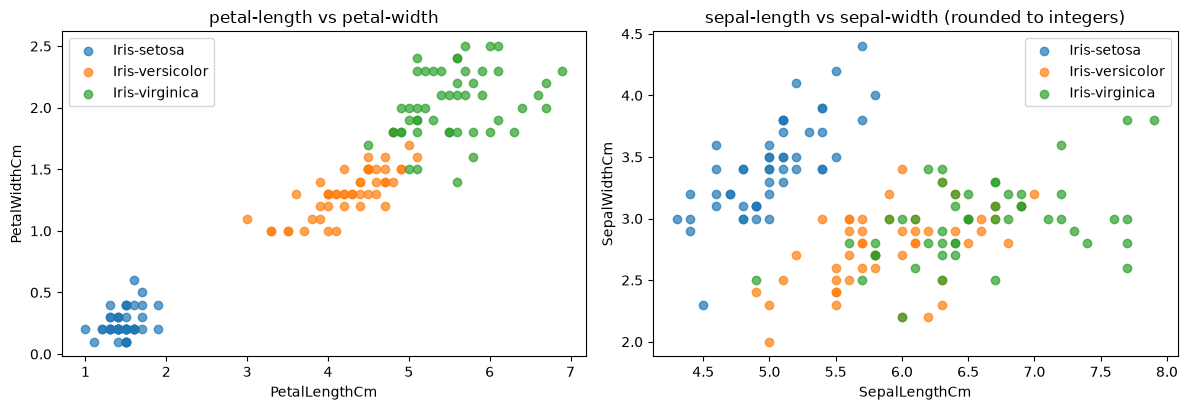

In [3]:
# petal-length vs petal-width: สอง feature นี้แยก class ได้ชัดที่สุด
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for k, name in enumerate(class_names):
    m = species_all == name
    ax[0].scatter(X_all[m, 2], X_all[m, 3], label=name, alpha=.7)
    ax[1].scatter(X_all[m, 0], X_all[m, 1], label=name, alpha=.7)
ax[0].set(title="petal-length vs petal-width", xlabel=FEATURES[2], ylabel=FEATURES[3]); ax[0].legend()
# sepal ถูกปัดเป็นจำนวนเต็ม จุดจึงซ้อนทับกันเป็นตาราง
ax[1].set(title="sepal-length vs sepal-width (rounded to integers)", xlabel=FEATURES[0], ylabel=FEATURES[1]); ax[1].legend()
fig.tight_layout(); plt.show()

In [4]:
# ข้อสังเกต: sepal ถูกปัดเป็นจำนวนเต็ม (Iris มาตรฐานมีทศนิยม 1 ตำแหน่ง)
for j, f in enumerate(FEATURES):
    print(f"{f:<14} เป็นจำนวนเต็มทุกตัว: {bool(np.all(X_all[:, j] == np.round(X_all[:, j])))}  ค่าที่ไม่ซ้ำ: {len(np.unique(X_all[:, j]))}")

# ผลที่ตามมา: มีแถวที่ feature เหมือนกันทุกตัวแต่ class ต่างกัน -> ไม่มีโมเดลไหนทายถูกได้ทั้งคู่
rows, inv = np.unique(X_all, axis=0, return_inverse=True)
inv = inv.ravel()
print(f"\nแถวที่ไม่ซ้ำกัน {len(rows)} จาก {len(X_all)} แถว")
for r in range(len(rows)):
    labels = set(species_all[inv == r])
    if len(labels) > 1:
        print("feature เหมือนกันแต่ class ต่างกัน:", rows[r], sorted(labels))

SepalLengthCm  เป็นจำนวนเต็มทุกตัว: False  ค่าที่ไม่ซ้ำ: 35
SepalWidthCm   เป็นจำนวนเต็มทุกตัว: False  ค่าที่ไม่ซ้ำ: 23
PetalLengthCm  เป็นจำนวนเต็มทุกตัว: False  ค่าที่ไม่ซ้ำ: 43
PetalWidthCm   เป็นจำนวนเต็มทุกตัว: False  ค่าที่ไม่ซ้ำ: 22

แถวที่ไม่ซ้ำกัน 147 จาก 150 แถว


## 1. เปรียบเทียบประสิทธิภาพและความเร็ว
ทุกวิธีเทรนด้วย train 80% แล้ววัดบน test 20% · จับเวลา fit และ predict ด้วย `compare()` ใน `ensemble.py`
เทียบ ensemble กับ base classifier ตัวเดียวที่ใช้ข้างใน: Bagging เทียบกับ Decision Tree เต็มต้น, AdaBoost เทียบกับ Decision Stump

Model                              Train acc  Test acc   Fit (s)  Predict (s)
Decision Tree (single)                1.0000    0.9667     0.001       0.0001
Bagging 50 trees (parallel)           1.0000    0.9667     1.795       0.0042
Bagging 50 trees (sequential)         1.0000    0.9667     0.036       0.0038
Decision Stump (single)               0.6667    0.6667     0.001       0.0001
AdaBoost SAMME 50 rounds              1.0000    0.9333     0.036       0.0037


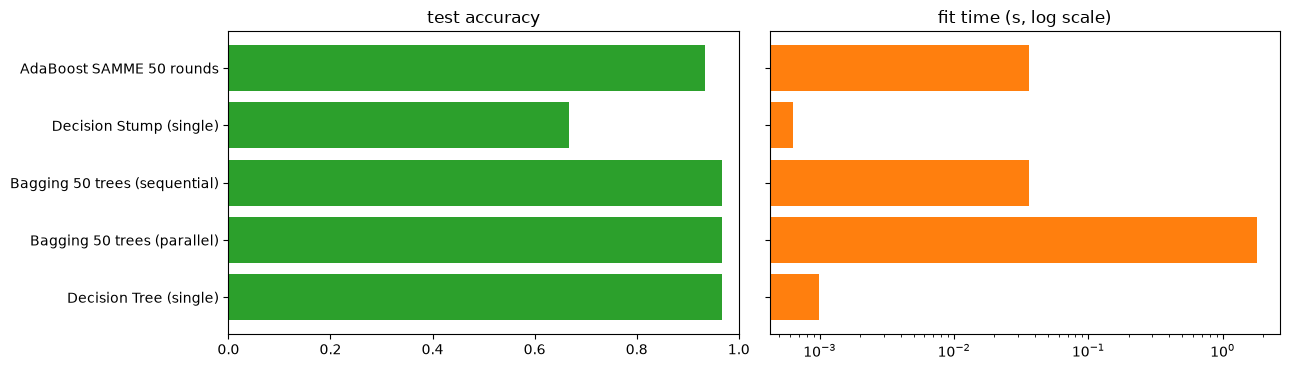

In [5]:
from ensemble import compare

rows = compare(X_tr, y_tr, X_te, y_te, n_estimators=50)
print(f"{'Model':<34}{'Train acc':>10}{'Test acc':>10}{'Fit (s)':>10}{'Predict (s)':>13}")
for r in rows:
    print(f"{r['model']:<34}{r['train_acc']:>10.4f}{r['test_acc']:>10.4f}{r['fit_s']:>10.3f}{r['predict_s']:>13.4f}")

# โมเดลที่ใช้ต่อในส่วนอื่น (seed เดียวกับในตาราง ผลจึงเหมือนกัน)
tree  = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
stump = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_tr, y_tr)
bag   = BaggingClassifier(n_estimators=50, parallel=False, seed=0).fit(X_tr, y_tr)
ada   = AdaBoostSAMME(n_estimators=50, seed=0).fit(X_tr, y_tr)

# กราฟแท่ง: accuracy และเวลา fit ของแต่ละวิธี
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
names = [r["model"] for r in rows]
ax[0].barh(names, [r["test_acc"] for r in rows], color="tab:green"); ax[0].set(xlim=(0, 1), title="test accuracy")
ax[1].barh(names, [r["fit_s"] for r in rows], color="tab:orange"); ax[1].set(xscale="log", title="fit time (s, log scale)")
ax[1].set_yticklabels([])
fig.tight_layout(); plt.show()

## 2. Accuracy ตามจำนวนโมเดลย่อย
เพราะ test set มีแค่ 45 ตัว ผลบน seed เดียวจึงแกว่ง กราฟ Bagging จึงเฉลี่ยจาก 10 seed

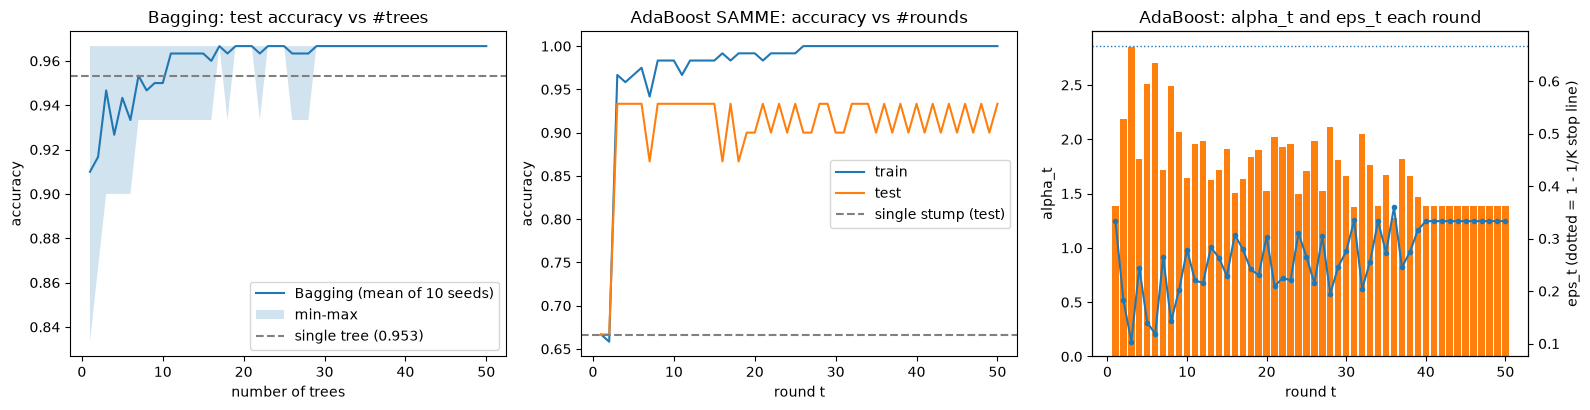

In [6]:
B = 50
bag_curves = np.array([BaggingClassifier(B, seed=s).fit(X_tr, y_tr).staged_score(X_te, y_te) for s in range(10)])
tree_acc = np.mean([accuracy(y_te, DecisionTreeClassifier(random_state=s).fit(X_tr, y_tr).predict(X_te)) for s in range(10)])

ada_test = ada.staged_score(X_te, y_te)
ada_train = ada.staged_score(X_tr, y_tr)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(1, B + 1)
ax[0].plot(x, bag_curves.mean(0), label="Bagging (mean of 10 seeds)")
ax[0].fill_between(x, bag_curves.min(0), bag_curves.max(0), alpha=.2, label="min-max")
ax[0].axhline(tree_acc, color="gray", ls="--", label=f"single tree ({tree_acc:.3f})")
ax[0].set(title="Bagging: test accuracy vs #trees", xlabel="number of trees", ylabel="accuracy")
ax[0].legend()

t = np.arange(1, len(ada.alphas_) + 1)
ax[1].plot(t, ada_train, label="train")
ax[1].plot(t, ada_test, label="test")
ax[1].axhline(accuracy(y_te, stump.predict(X_te)), color="gray", ls="--", label="single stump (test)")
ax[1].set(title="AdaBoost SAMME: accuracy vs #rounds", xlabel="round t", ylabel="accuracy")
ax[1].legend()

ax[2].bar(t, ada.alphas_, color="tab:orange", label="alpha_t")
ax2 = ax[2].twinx()
ax2.plot(t, ada.errors_, color="tab:blue", marker=".", label="weighted error eps_t")
ax2.axhline(1 - 1/3, color="tab:blue", ls=":", lw=1)
ax[2].set(title="AdaBoost: alpha_t and eps_t each round", xlabel="round t", ylabel="alpha_t")
ax2.set_ylabel("eps_t (dotted = 1 - 1/K stop line)")
fig.tight_layout(); plt.show()

### 2.1 ตรวจ ε และ α รอบแรกด้วยมือ
รอบแรกทุกตัวอย่างมีน้ำหนัก 1/n เท่ากัน ε₁ จึงเท่ากับ (จำนวนที่ทายผิด) / n ตรงๆ แล้ว α₁ = ln((1−ε₁)/ε₁) + ln(K−1)

In [7]:
# stump รอบแรกเทรนด้วยน้ำหนักเท่ากัน จึงเหมือน stump ธรรมดา
first = ada.estimators_[0]
miss1 = first.predict(X_tr) != y_tr
n, K = len(y_tr), 3
eps1 = miss1.sum() / n                       # น้ำหนักเท่ากัน -> นับจำนวนผิดหาร n ได้เลย
alpha1 = np.log((1 - eps1) / eps1) + np.log(K - 1)
print(f"stump รอบแรกแบ่งด้วย {FEATURES[first.tree_.feature[0]]} <= {first.tree_.threshold[0]:.2f}")
print(f"ทายผิด {miss1.sum()} จาก {n} ตัว -> eps_1 = {eps1:.4f}   (ada.errors_[0] = {ada.errors_[0]:.4f})")
print(f"alpha_1 = ln({1-eps1:.4f}/{eps1:.4f}) + ln({K-1}) = {alpha1:.4f}   (ada.alphas_[0] = {ada.alphas_[0]:.4f})")
# stump ลึก 1 ชั้นแบ่งได้แค่ 2 ฝั่ง จึงทายได้แค่ 2 จาก 3 class -> ผิดทั้ง class ที่เหลือ (35 ตัว = 1/3)
print("class ที่ stump ทาย:", np.unique(first.predict(X_tr)))

stump รอบแรกแบ่งด้วย PetalWidthCm <= 0.80
ทายผิด 40 จาก 120 ตัว -> eps_1 = 0.3333   (ada.errors_[0] = 0.3333)
alpha_1 = ln(0.6667/0.3333) + ln(2) = 1.3863   (ada.alphas_[0] = 1.3863)
class ที่ stump ทาย: [0 1]


## 3. Bagging: Parallel vs Sequential
จับเวลาการ `fit` ของ Bagging แบบขนาน (ProcessPoolExecutor) เทียบกับแบบวนลูปธรรมดา

B=   10  parallel 1.796s   sequential 0.008s


B=   50  parallel 1.773s   sequential 0.036s


B=  200  parallel 1.813s   sequential 0.137s


B= 1000  parallel 1.931s   sequential 0.698s


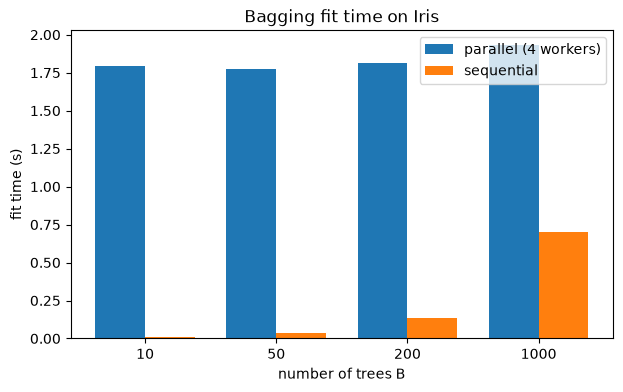

In [8]:
import os
sizes = [10, 50, 200, 1000]
t_par, t_seq = [], []
for b in sizes:
    t0 = time.perf_counter(); BaggingClassifier(b, parallel=True,  seed=0).fit(X_tr, y_tr); t_par.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); BaggingClassifier(b, parallel=False, seed=0).fit(X_tr, y_tr); t_seq.append(time.perf_counter() - t0)
    print(f"B={b:5d}  parallel {t_par[-1]:.3f}s   sequential {t_seq[-1]:.3f}s")

w = 0.38; xi = np.arange(len(sizes))
plt.figure(figsize=(7, 4))
plt.bar(xi - w/2, t_par, w, label=f"parallel ({BaggingClassifier().max_workers} workers)")
plt.bar(xi + w/2, t_seq, w, label="sequential")
plt.xticks(xi, sizes); plt.xlabel("number of trees B"); plt.ylabel("fit time (s)")
plt.title("Bagging fit time on Iris"); plt.legend(); plt.show()

### 3.1 เมื่อไหร่ parallel ถึงเร็วกว่า
ผลข้างบน parallel ช้ากว่า เพราะต้นทุนการเปิด process สูงกว่างานที่แบ่งไปทำ
- จากการวัด: worker ถูกเปิด**ต่อกันทีละตัว ตัวละราว 1.3 s** (แต่ละ process ต้อง import numpy/sklearn ใหม่) เปิด 4 ตัวจึงเสียราว 5 s
- เทรน DT บน Iris ใช้ต้นละไม่ถึง 1 ms จึงไม่มีทางคุ้ม

parallel จะคุ้มเมื่อโมเดลย่อยแต่ละตัว**เทรนนาน**กว่าต้นทุนนี้มากพอ จึงทดลองดังนี้
- **base model = SVM** (`SVC`, โจทย์อนุญาต) เวลาเทรนโตประมาณ n² แต่โมเดลที่ได้มีขนาดเล็ก ส่งกลับข้าม process ได้เร็ว
  - DT บนข้อมูลใหญ่จะโตลึกมาก ต้นทุนไปอยู่ที่การส่งต้นไม้กลับ ไม่ใช่การเทรน จึงไม่เหมาะกับการวัดนี้
- **ข้อมูล = Iris ขยายขนาด**: สุ่ม Iris train แบบใส่คืนให้ได้ n ตัว แล้วบวก noise (σ = 0.8) ให้ class ซ้อนกันมากขึ้น SVM จะมี support vector มากขึ้นและเทรนนานขึ้น ยังเป็น 4 feature 3 class เหมือนเดิม
- B = 16 โมเดล, 4 process (เวลา parallel รวมเวลาเปิด process แล้ว)

n= 2000  parallel   1.83s   sequential   0.29s   speedup x0.16   (test acc 0.933)


n= 5000  parallel   5.37s   sequential   2.00s   speedup x0.37   (test acc 0.900)


n=10000  parallel   6.59s   sequential   8.19s   speedup x1.24   (test acc 0.900)


n=20000  parallel  13.87s   sequential  32.27s   speedup x2.33   (test acc 0.900)


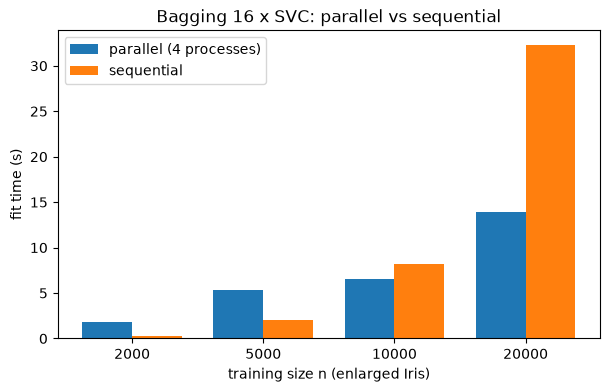

In [9]:
from sklearn.svm import SVC

def enlarge_iris(n, sigma=0.8, seed=0):
    """สุ่ม Iris train แบบใส่คืนให้ได้ n ตัว + บวก Gaussian noise"""
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(X_tr), n)
    return X_tr[idx] + rng.normal(0, sigma, (n, X_tr.shape[1])), y_tr[idx]

sizes_n = [2000, 5000, 10000, 20000]
res = []
for n in sizes_n:
    Xb, yb = enlarge_iris(n)
    row = {}
    for mode in (True, False):
        t0 = time.perf_counter()
        m = BaggingClassifier(16, max_workers=4, parallel=mode, seed=0, base=SVC(C=10)).fit(Xb, yb)
        row["parallel" if mode else "sequential"] = time.perf_counter() - t0
    res.append(row)
    print(f"n={n:5d}  parallel {row['parallel']:6.2f}s   sequential {row['sequential']:6.2f}s   "
          f"speedup x{row['sequential'] / row['parallel']:.2f}   (test acc {accuracy(y_te, m.predict(X_te)):.3f})")

xi = np.arange(len(sizes_n)); w = 0.38
plt.figure(figsize=(7, 4))
plt.bar(xi - w/2, [r["parallel"] for r in res], w, label="parallel (4 processes)")
plt.bar(xi + w/2, [r["sequential"] for r in res], w, label="sequential")
plt.xticks(xi, sizes_n); plt.xlabel("training size n (enlarged Iris)"); plt.ylabel("fit time (s)")
plt.title("Bagging 16 x SVC: parallel vs sequential"); plt.legend(); plt.show()

## 4. Confusion matrix บน test set

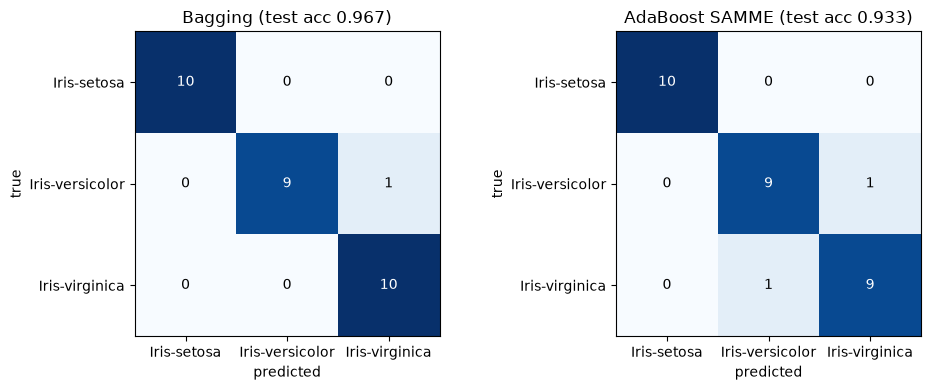

In [10]:
def confusion(y, p, K=3):
    cm = np.zeros((K, K), int)
    np.add.at(cm, (y, p), 1)  # แถว = class จริง, คอลัมน์ = class ที่ทาย
    return cm

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, m) in zip(ax, [("Bagging", bag), ("AdaBoost SAMME", ada)]):
    cm = confusion(y_te, m.predict(X_te))
    a.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    a.set(title=f"{name} (test acc {accuracy(y_te, m.predict(X_te)):.3f})", xlabel="predicted", ylabel="true",
          xticks=range(3), yticks=range(3), xticklabels=class_names, yticklabels=class_names)
fig.tight_layout(); plt.show()

## 5. วิเคราะห์ผล
ตัวเลขทุกตัวมาจากผลที่รันได้ด้านบน (test set 45 ตัว: ทายผิดเพิ่ม 1 ตัว = accuracy ลด 0.0222)

**1. Bagging ดีกว่า Decision Tree ต้นเดียวไหม?**
ไม่ดีกว่าบน Iris ชุดนี้: Decision Tree ต้นเดียวได้ test 0.9333 ส่วน Bagging 50 ต้นได้ 0.9111 (seed 0) และค่าเฉลี่ย 10 seed ในกราฟส่วนที่ 2 ก็อยู่ใต้เส้น single tree ต่างกันแค่ 1 ตัวอย่าง (2.2%) จึงสรุปไม่ได้ว่าแย่กว่าจริง เหตุที่เห็นผลต่างน้อย:
- ข้อมูลง่าย: ส่วนที่ 0 แสดงว่า petal-width/petal-length แยก setosa ได้ขาด และแยก versicolor/virginica ได้เกือบหมด ต้นเดียวก็ทำได้ดีอยู่แล้ว variance ที่ Bagging ช่วยลดจึงมีน้อย
- train accuracy ของทุกโมเดลตันที่ 0.9905 เพราะมีแถว `[6, 3, 4.8, 1.8]` ที่ feature เหมือนกันแต่เป็นทั้ง versicolor และ virginica (ผลจาก sepal ถูกปัดเป็นจำนวนเต็ม ดูส่วนที่ 0)
- test 45 ตัว ผลต่าง 1 ตัวอยู่ในระดับ noise

**2. AdaBoost ยก stump ขึ้นมาได้เท่าไหร่ และ train accuracy เป็นอย่างไรตามจำนวนรอบ**
stump ตัวเดียวได้ 0.6667 ทั้ง train และ test เพราะแบ่งได้ครั้งเดียว (`petal-width <= 0.70`) จึงทายได้แค่ 2 class ผิดทั้ง class ที่เหลือ 35 ตัว (ส่วนที่ 2.1) AdaBoost 50 รอบยก test เป็น 0.9111 และ train เป็น 0.9905
- train accuracy เพิ่มเป็นขั้นบันได: รอบ 1–2 ยัง 0.6667, รอบ 3 กระโดดเป็น 0.9714 (stump ใหม่แยก versicolor/virginica ได้), ถึง 0.9905 ที่รอบ 19 แล้วคงที่ ไม่ถึง 1.0 เพราะแถวที่ขัดกันแถวเดียว
- ไม่ overfit ชัดเจน แต่ test แกว่ง 0.9111 ↔ 0.9333 ทุกรอบช่วงท้าย (ดูข้อ 3) ค่าที่ T=10 (0.9333) จึงดีกว่า T=50 (0.9111) แค่ 1 ตัวอย่าง

**3. α_t สัมพันธ์กับ ε_t อย่างไร**
α_t = ln((1−ε_t)/ε_t) + ln(K−1) ลดลงเมื่อ ε_t เพิ่ม: stump ที่แม่นกว่าได้เสียงโหวตมากกว่า ในกราฟขวาของส่วนที่ 2 แท่ง α สูงตรงรอบที่ ε ต่ำ เช่น รอบ 3 ε ต่ำสุด 0.101 ได้ α สูงสุด 2.88 ส่วนรอบ 1 ε = 1/3 ได้ α = ln 2 + ln 2 = 1.386 (ตรวจด้วยมือในส่วนที่ 2.1 ตรงกับ `ada.errors_[0]`, `ada.alphas_[0]`)
- ε_t มีแนวโน้มเพิ่มขึ้นตามรอบ เพราะน้ำหนักไปกองที่ตัวอย่างยาก stump รอบหลังๆ จึงทำได้แย่ลง
- ตั้งแต่รอบ 35 ε_t = 1/3 พอดีทุกรอบ (ยังต่ำกว่าเส้นหยุด 2/3) น้ำหนักรวมของแต่ละ class เท่ากันพอดีที่ 1/3 stump ที่ได้จึงผิด 1/3 พอดี (เช่น รอบ 35 ทาย virginica อย่างเดียว, รอบ 36 กลับไปเป็น `petal-width <= 0.70` แบบรอบแรก) และได้ α = 1.386 เท่ากันทุกรอบ การโหวตจึงพลิกไปมา ทำให้ test accuracy แกว่ง 0.9111/0.9333 สลับรอบ

**4. ทำไม parallel ช้ากว่า sequential บน Iris และจะคุ้มเมื่อไหร่**
จากส่วนที่ 3: parallel ใช้ราว 2.4–2.7 s เกือบคงที่ทุก B ส่วน sequential โตตาม B (B=1000 ใช้ 0.527 s ≈ 0.5 ms ต่อต้น)
- เวลาของ parallel แทบทั้งหมดคือ overhead คงที่: เปิด worker 4 process (`min(4, cpu)`) บน Windows ต้อง spawn Python ใหม่และ import numpy/sklearn ทุก process, ส่ง X, y ผ่าน `initializer`, และส่งต้นไม้ที่เทรนเสร็จ (pickle) กลับมา งานเทรน DT บนข้อมูล 105 ตัวเล็กกว่า overhead นี้หลายเท่า
- คุ้มเมื่องานรวมใหญ่กว่า overhead: ประมาณคร่าวๆ จากตัวเลขข้างบน overhead ≈ 2.4 s และ 4 worker ลดเวลางานได้สูงสุดราว 3/4 จุดคุ้มทุนจึงอยู่ที่งานรวมแบบ sequential ราว 3 วินาที (≈ 6,000 ต้นบน Iris) หรือเมื่อแต่ละโมเดลเทรนนานขึ้น เช่น ข้อมูลหลักหมื่นแถวขึ้นไป หรือ base classifier ที่หนักกว่า (SVM) ถ้า pool ถูกเปิดค้างไว้ใช้ซ้ำ overhead ก็จะเสียแค่ครั้งเดียว
- ผลวัดจริงในส่วนที่ 3.1 ยืนยันแนวนี้: เมื่อใช้ base = SVM บน Iris ขยายขนาด parallel เริ่มเร็วกว่าที่ n = 10,000 และเร็วกว่าราว 2 เท่าที่ n = 20,000

**5. class ไหนสับสนกันบ่อยที่สุด**
versicolor กับ virginica ทั้ง Bagging และ AdaBoost ได้ confusion matrix เหมือนกัน: setosa ถูกหมด 15/15, versicolor ทายเป็น virginica 1 ตัว, virginica ทายเป็น versicolor 3 ตัว (ผิด 4 ตัว = 0.9111) สอดคล้องกับ scatter ในส่วนที่ 0 ที่ setosa แยกขาด แต่ versicolor/virginica ซ้อนกันในช่วง petal-length 4.5–5.1 และ petal-width 1.4–1.8 และแถวที่ขัดกันก็อยู่ระหว่างสอง class นี้


## 6. (เพิ่มเติม) AdaBoost: Decision Stump vs ต้นลึก 2 ชั้น
weak learner ที่แรงขึ้น (max_depth=2) ช่วยหรือไม่

weak learner       T  rounds   Train    Test
max_depth=1       10      10  0.9833  0.9333
max_depth=1       50      50  1.0000  0.9333
max_depth=2       10      10  1.0000  0.9333
max_depth=2       50      50  1.0000  0.9667
single depth-2                0.9667  0.9333


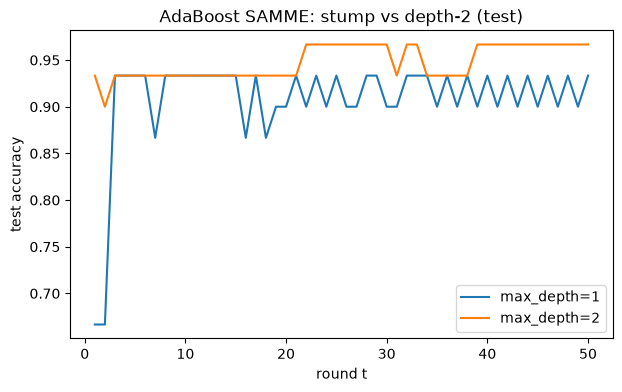

In [11]:
print(f"{'weak learner':<16}{'T':>4}{'rounds':>8}{'Train':>8}{'Test':>8}")
curves = {}
for depth in [1, 2]:
    for T in [10, 50]:
        a = AdaBoostSAMME(n_estimators=T, max_depth=depth, seed=0).fit(X_tr, y_tr)
        print(f"{'max_depth=' + str(depth):<16}{T:>4}{len(a.alphas_):>8}"
              f"{accuracy(y_tr, a.predict(X_tr)):>8.4f}{accuracy(y_te, a.predict(X_te)):>8.4f}")
        curves[depth] = a.staged_score(X_te, y_te)  # เก็บกราฟของ T=50
# เทียบกับต้นลึก 2 ชั้นต้นเดียว (ไม่ boosting)
d2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_tr, y_tr)
print(f"{'single depth-2':<16}{'':>4}{'':>8}{accuracy(y_tr, d2.predict(X_tr)):>8.4f}{accuracy(y_te, d2.predict(X_te)):>8.4f}")

plt.figure(figsize=(7, 4))
for depth, c in curves.items():
    plt.plot(np.arange(1, len(c) + 1), c, label=f"max_depth={depth}")
plt.xlabel("round t"); plt.ylabel("test accuracy")
plt.title("AdaBoost SAMME: stump vs depth-2 (test)"); plt.legend(); plt.show()

**สรุปส่วนที่ 6**: weak learner ที่แรงขึ้นทำให้ train ลู่เข้าเร็วขึ้น (max_depth=2 ได้ 0.9905 ตั้งแต่ T=10 ส่วน stump ต้องใช้ ~19 รอบ) แต่ test ไม่ดีขึ้น: ทั้งสองแบบได้ 0.9111 ที่ T=50 และ stump T=10 ได้ 0.9333 ซึ่งต่างกันแค่ 1 ตัวอย่าง AdaBoost ยกต้นลึก 2 ชั้นต้นเดียว (test 0.8889) ขึ้นได้แค่ 1 ตัวอย่าง เพราะต้นลึก 2 ชั้นแรงพอจะแยก 3 class ได้อยู่แล้ว เหลือ bias ให้ boosting ลดน้อย บน Iris เพดานถูกจำกัดด้วยข้อมูล (แถวที่ขัดกัน + test 45 ตัว) มากกว่าความแรงของ weak learner จึงใช้ stump ตามทฤษฎี AdaBoost ต่อไปได้
